# 6001CMD – Group Project: Credit Card Customer Attrition
**Comparative Machine Learning Modelling and Ensemble Learning**  
Parts A–G · Dataset: `BankChurners.csv` · Classification: `Attrition_Flag` (0=Existing, 1=Attrited)

**How to run:** Put `BankChurners.csv` alongside this notebook (or upload it in Colab), then choose **Runtime → Restart and run all**. Only Part G accesses the untouched hold-out test set for performance assessment. The processed CSV is an export for submission; **do not use that export for model training/CV** because it has been transformed using a preprocessor fitted on the full training partition.

**Audit corrections:** all three base models have executable training code; categorical-aware SMOTENC is fitted *inside each CV training fold*; preprocessor fitting is also fold-contained; the two-model Voting ensemble is chosen on training CV results only; no test outcomes guide preprocessing, hyperparameters, or ensemble selection. All plots and figures reflect freshly executed runs rather than cached outputs.

*Dataset source:* https://www.kaggle.com/datasets/sakshigoyal7/credit-card-customers. The downloadable file is a public sample. Do not assert a specific bank or independently verified acquisition process; historical transaction volume is not proven lost revenue. The business recall threshold of 0.85 is an illustrative goal, not an externally validated benchmark.

## Environment & input data
Use the same environment throughout. Dependencies: `pandas`, `numpy`, `matplotlib`, `seaborn`, `scikit-learn`, `imbalanced-learn`, `scipy`, `nbformat` (only needed to edit notebooks).

In [23]:
# In a fresh Colab runtime, install only if needed:
# %pip install -q scikit-learn imbalanced-learn pandas numpy matplotlib seaborn
from pathlib import Path
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.base import clone

RANDOM_STATE = 42
CV_SPLITS = 3      # Same CV partitions for baseline, tuning, and ensemble checks
DATA_PATH = Path('/BankChurners.csv')
if not DATA_PATH.is_file() and Path('/mnt/data/BankChurners.csv').is_file():
    DATA_PATH = Path('/mnt/data/BankChurners.csv')
if not DATA_PATH.is_file():
    raise FileNotFoundError('Place BankChurners.csv next to this notebook or upload it to Colab first.')
print('Reading:', DATA_PATH.resolve())
print('Current directory:', Path.cwd())

Reading: /BankChurners.csv
Current directory: /content


## Part A — Problem definition and dataset audit (5 marks)
**Business setting:** A credit-card issuer wants to identify potentially attriting clients before they leave, supporting targeted customer retention. **Objective:** binary classification of `Attrition_Flag` with 1 meaning attrited. **Success criteria:** compare F1 and ROC-AUC, prioritising minority-class recall while monitoring false positives, model cost and generalisation. A recall of 0.85 is an **illustrative**, not validated, business threshold.

**Important limit:** features such as total transaction volume may be measured over the same historical period as churn. The dataset documentation does not demonstrate that every predictor was known *before* customer attrition. This is a retrospective classification proof-of-concept, not a validated prospective early-warning system.

In [11]:
# ==============================================================================
# PART A: DATASET VERIFICATION & INITIAL AUDIT
# ==============================================================================
import pandas as pd
import numpy as np

# 1. Load the raw dataset and remove pre-computed Naive Bayes artifact columns
df_raw = pd.read_csv(DATA_PATH)
nb_cols = [col for col in df_raw.columns if col.startswith('Naive_Bayes_Classifier')]
df_audit = df_raw.drop(columns=nb_cols)

# 2. Verify rubric constraints (>= 5,000 rows and >= 10 attributes)
n_rows, n_cols = df_audit.shape
print(f"Raw File Dimensions: {df_raw.shape[0]:,} records x {df_raw.shape[1]} columns")
print(f"Audited Dataset Dimensions (excluding NB artifacts): {n_rows:,} records x {n_cols} attributes")
assert n_rows >= 5000, "Dataset violates minimum 5,000 records requirement!"
assert n_cols >= 10, "Dataset violates minimum 10 attributes requirement!"

# 3. Inspect target distribution and financial exposure
churn_counts = df_audit['Attrition_Flag'].value_counts()
churn_pct = df_audit['Attrition_Flag'].value_counts(normalize=True) * 100

avg_trans_amt = df_audit['Total_Trans_Amt'].mean()
avg_rev_bal = df_audit['Total_Revolving_Bal'].mean()

attrited_df = df_audit[df_audit['Attrition_Flag'] == 'Attrited Customer']
lost_trans_volume = attrited_df['Total_Trans_Amt'].sum()
lost_revolving_bal = attrited_df['Total_Revolving_Bal'].sum()

print("\n--- Target Variable Distribution (Attrition_Flag) ---")
for label in ['Existing Customer', 'Attrited Customer']:
    print(f"{label:18s}: {churn_counts[label]:,} customers ({churn_pct[label]:.2f}%)")

print("\n--- Business & Financial Exposure Audit ---")
print(f"Mean Recorded Transaction Amount           : {avg_trans_amt:,.2f} dataset units/customer")
print(f"Average Revolving Balance                   : {avg_rev_bal:,.2f} dataset units/customer")
print(f"Historical Transaction Volume (Attrited)   : {lost_trans_volume:,.2f} dataset units")
print(f"Recorded Revolving Balance (Attrited)      : {lost_revolving_bal:,.2f} dataset units")

Raw File Dimensions: 10,127 records x 23 columns
Audited Dataset Dimensions (excluding NB artifacts): 10,127 records x 21 attributes

--- Target Variable Distribution (Attrition_Flag) ---
Existing Customer : 8,500 customers (83.93%)
Attrited Customer : 1,627 customers (16.07%)

--- Business & Financial Exposure Audit ---
Mean Recorded Transaction Amount           : 4,404.09 dataset units/customer
Average Revolving Balance                   : 1,162.81 dataset units/customer
Historical Transaction Volume (Attrited)   : 5,035,607.00 dataset units
Recorded Revolving Balance (Attrited)      : 1,094,683.00 dataset units


## Part B — Exploratory data analysis (10 marks)
Interpret descriptive statistics, explicit/implicit missingness, target imbalance, feature distributions, correlation, and IQR outliers. An IQR outlier is a statistical flag rather than proof that a value should be removed. No test-set modelling decisions should be made from these plots.

=== 1. DESCRIPTIVE STATISTICS & DISTRIBUTION SHAPE ===
                            count      mean    median       std     min  \
Customer_Age              10127.0    46.326    46.000     8.017    26.0   
Dependent_count           10127.0     2.346     2.000     1.299     0.0   
Months_on_book            10127.0    35.928    36.000     7.986    13.0   
Total_Relationship_Count  10127.0     3.813     4.000     1.554     1.0   
Months_Inactive_12_mon    10127.0     2.341     2.000     1.011     0.0   
Contacts_Count_12_mon     10127.0     2.455     2.000     1.106     0.0   
Credit_Limit              10127.0  8631.954  4549.000  9088.777  1438.3   
Total_Revolving_Bal       10127.0  1162.814  1276.000   814.987     0.0   
Avg_Open_To_Buy           10127.0  7469.140  3474.000  9090.685     3.0   
Total_Amt_Chng_Q4_Q1      10127.0     0.760     0.736     0.219     0.0   
Total_Trans_Amt           10127.0  4404.086  3899.000  3397.129   510.0   
Total_Trans_Ct            10127.0    64.859  

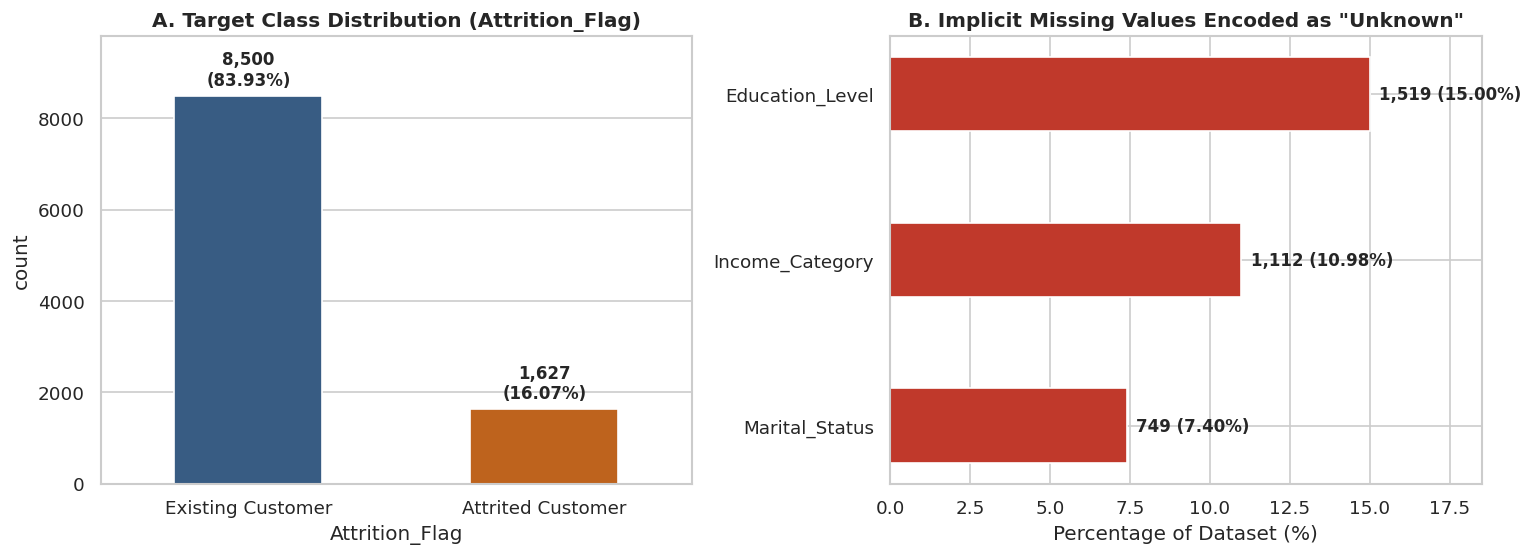

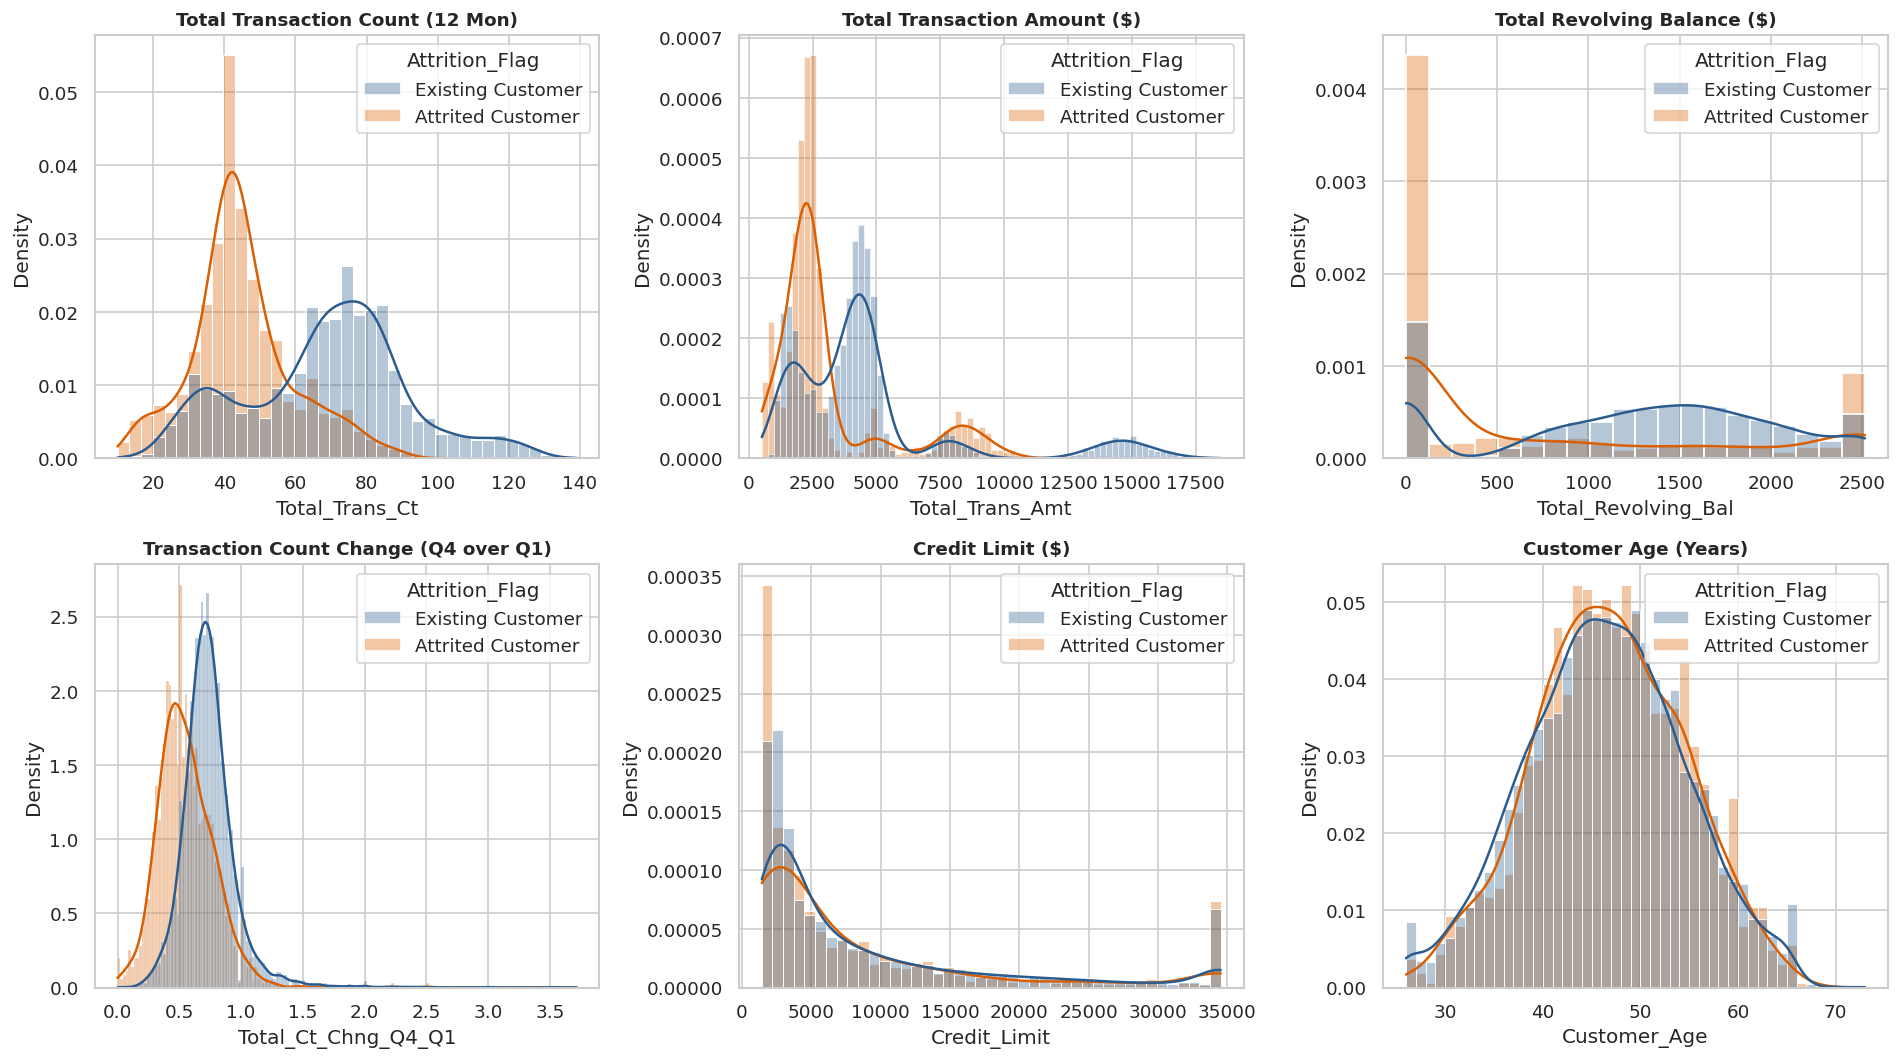

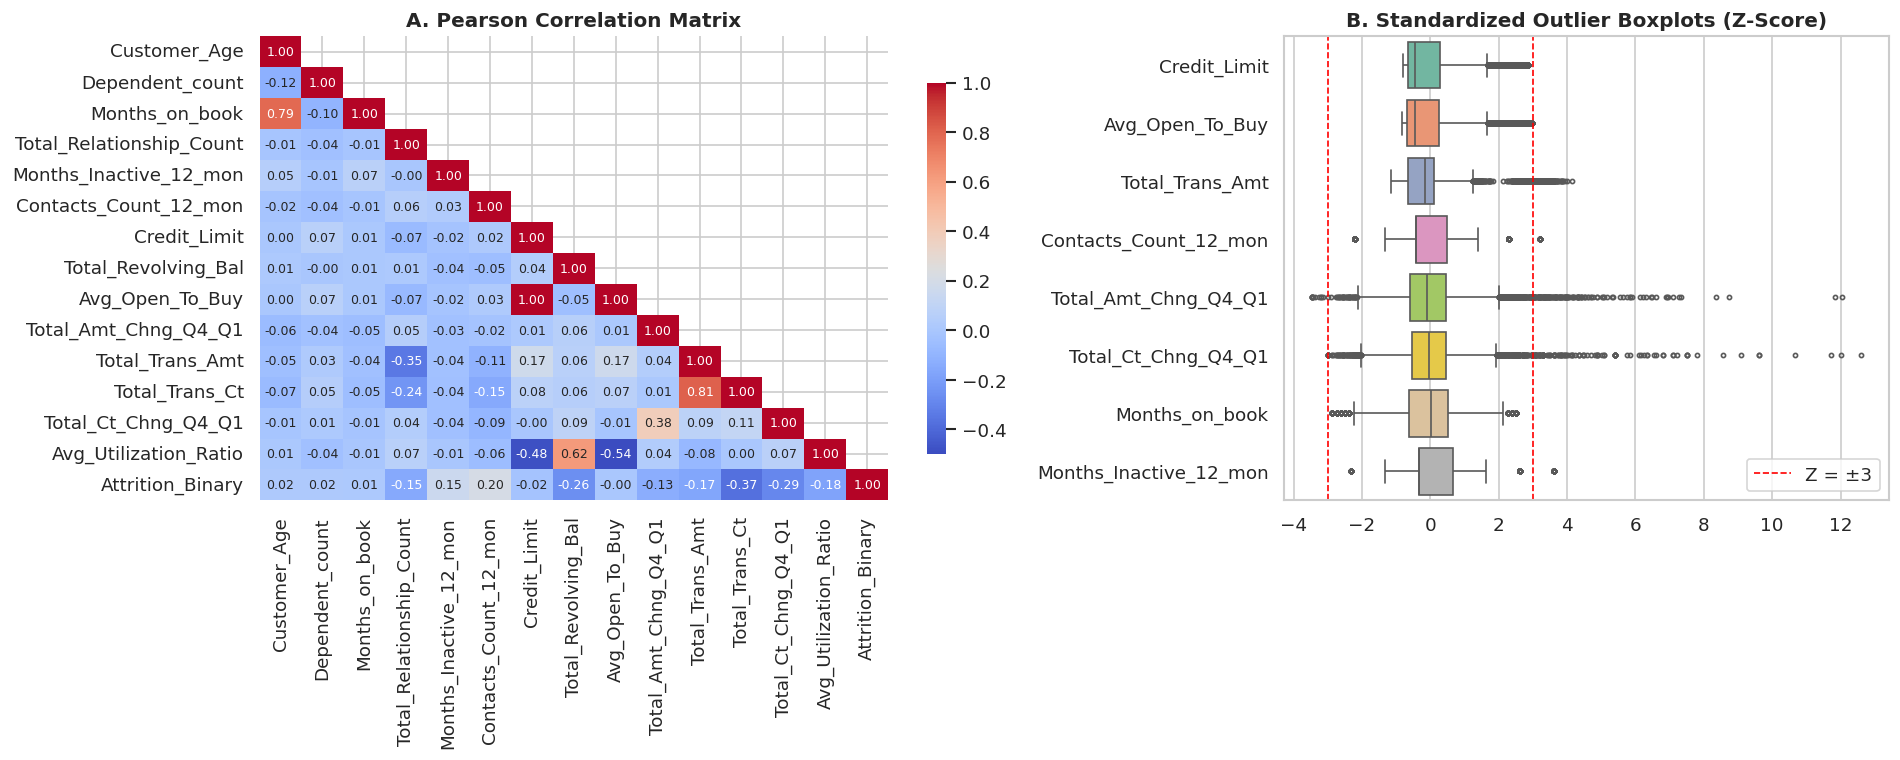

In [12]:
# ==============================================================================
# PART B: EXPLORATORY DATA ANALYSIS (EDA)
# ==============================================================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.dpi'] = 120

# 1. Prepare clean EDA dataframe (drop ID and Naive Bayes leakage columns)
nb_cols = [c for c in df_raw.columns if c.startswith('Naive_Bayes_Classifier')]
df_eda = df_raw.drop(columns=['CLIENTNUM'] + nb_cols).copy()
df_eda['Attrition_Binary'] = (df_eda['Attrition_Flag'] == 'Attrited Customer').astype(int)

num_cols = df_eda.select_dtypes(include=[np.number]).drop(columns=['Attrition_Binary']).columns.tolist()
cat_cols = df_eda.select_dtypes(include=['object']).drop(columns=['Attrition_Flag']).columns.tolist()

# 2. Descriptive Statistics, Skewness & Kurtosis
desc_stats = df_eda[num_cols].describe().T[['count', 'mean', '50%', 'std', 'min', 'max']]
desc_stats.rename(columns={'50%': 'median'}, inplace=True)
desc_stats['skewness'] = df_eda[num_cols].skew()
desc_stats['kurtosis'] = df_eda[num_cols].kurt()
print("=== 1. DESCRIPTIVE STATISTICS & DISTRIBUTION SHAPE ===")
print(desc_stats.round(3))

# 3. Explicit (NaN) vs. Implicit ('Unknown') Missing Value Audit
print("\n=== 2. MISSING VALUE AUDIT (EXPLICIT NaN vs IMPLICIT 'Unknown') ===")
missing_report = []
for col in df_eda.drop(columns=['Attrition_Binary']).columns:
    nan_ct = df_eda[col].isna().sum()
    unk_ct = (df_eda[col] == 'Unknown').sum() if df_eda[col].dtype == 'object' else 0
    missing_report.append({
        'Feature': col,
        'Dtype': str(df_eda[col].dtype),
        'Explicit_NaN': nan_ct,
        'Implicit_Unknown': unk_ct,
        'Total_Missing_Pct': round((nan_ct + unk_ct) / len(df_eda) * 100, 2)
    })
missing_df = pd.DataFrame(missing_report)
print(missing_df[missing_df['Total_Missing_Pct'] > 0].to_string(index=False))

# 4. Outlier Detection via 1.5x IQR Rule
print("\n=== 3. OUTLIER ANALYSIS (1.5x IQR RULE) ===")
outlier_rows = []
for col in num_cols:
    Q1, Q3 = df_eda[col].quantile(0.25), df_eda[col].quantile(0.75)
    IQR = Q3 - Q1
    outliers = ((df_eda[col] < (Q1 - 1.5 * IQR)) | (df_eda[col] > (Q3 + 1.5 * IQR))).sum()
    outlier_rows.append({
        'Feature': col, 'Q1': round(Q1, 2), 'Q3': round(Q3, 2), 'IQR': round(IQR, 2),
        'Outlier_Count': outliers, 'Outlier_Pct': round(outliers / len(df_eda) * 100, 2)
    })
outlier_df = pd.DataFrame(outlier_rows).sort_values(by='Outlier_Pct', ascending=False)
print(outlier_df.to_string(index=False))

# 5. Visualisations (Target & Missingness, Feature Distributions, Correlation & Outliers)
palette_target = ['#2b5c8f', '#d95f02']

# --- FIGURE 1: Target Imbalance & Implicit Missing Values ---
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
ax1 = sns.countplot(data=df_eda, x='Attrition_Flag', hue='Attrition_Flag', legend=False, palette=palette_target, ax=axes[0], width=0.5)
axes[0].set_title('A. Target Class Distribution (Attrition_Flag)', fontsize=12, fontweight='bold')
axes[0].set_ylim(0, 9800)
for p in ax1.patches:
    ct = int(p.get_height())
    ax1.annotate(f'{ct:,}\n({100*ct/len(df_eda):.2f}%)', (p.get_x() + p.get_width()/2., ct),
                 ha='center', va='bottom', fontsize=10, fontweight='bold', xytext=(0, 4), textcoords='offset points')

unk_subset = missing_df[missing_df['Total_Missing_Pct'] > 0].sort_values(by='Total_Missing_Pct', ascending=True)
bars = axes[1].barh(unk_subset['Feature'], unk_subset['Total_Missing_Pct'], color='#c0392b', height=0.45)
axes[1].set_title('B. Implicit Missing Values Encoded as "Unknown"', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Percentage of Dataset (%)')
axes[1].set_xlim(0, 18.5)
for bar, (_, row) in zip(bars, unk_subset.iterrows()):
    axes[1].annotate(f"{int(row['Implicit_Unknown']):,} ({row['Total_Missing_Pct']:.2f}%)",
                     (bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2),
                     va='center', ha='left', fontsize=10, fontweight='bold')
plt.tight_layout()
plt.show()

# --- FIGURE 2: Stratified KDE & Histogram Distributions ---
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
key_dist_cols = [
    ('Total_Trans_Ct', 'Total Transaction Count (12 Mon)'),
    ('Total_Trans_Amt', 'Total Transaction Amount ($)'),
    ('Total_Revolving_Bal', 'Total Revolving Balance ($)'),
    ('Total_Ct_Chng_Q4_Q1', 'Transaction Count Change (Q4 over Q1)'),
    ('Credit_Limit', 'Credit Limit ($)'),
    ('Customer_Age', 'Customer Age (Years)')
]
for ax, (col, title) in zip(axes.flatten(), key_dist_cols):
    sns.histplot(data=df_eda, x=col, hue='Attrition_Flag', kde=True,
                 stat='density', common_norm=False, palette=palette_target, alpha=0.35, ax=ax)
    ax.set_title(title, fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

# --- FIGURE 3: Correlation Heatmap & Standardized Outlier Boxplots ---
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5), gridspec_kw={'width_ratios': [1.3, 1]})
corr_matrix = df_eda[num_cols + ['Attrition_Binary']].corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool), k=1)
sns.heatmap(corr_matrix, mask=mask, annot=True, fmt='.2f', cmap='coolwarm',
            vmin=-0.5, vmax=1.0, cbar_kws={'shrink': 0.8}, annot_kws={'size': 7.5}, ax=axes[0])
axes[0].set_title('A. Pearson Correlation Matrix', fontsize=12, fontweight='bold')

top_outlier_cols = ['Credit_Limit', 'Avg_Open_To_Buy', 'Total_Trans_Amt',
                    'Contacts_Count_12_mon', 'Total_Amt_Chng_Q4_Q1', 'Total_Ct_Chng_Q4_Q1',
                    'Months_on_book', 'Months_Inactive_12_mon']
df_z = (df_eda[top_outlier_cols] - df_eda[top_outlier_cols].mean()) / df_eda[top_outlier_cols].std()
sns.boxplot(data=df_z, orient='h', palette='Set2', fliersize=2.5, ax=axes[1])
axes[1].set_title('B. Standardized Outlier Boxplots (Z-Score)', fontsize=12, fontweight='bold')
axes[1].axvline(3, color='red', linestyle='--', linewidth=1, label='Z = ±3')
axes[1].axvline(-3, color='red', linestyle='--', linewidth=1)
axes[1].legend(loc='lower right')
plt.tight_layout()
plt.show()

## Part C — Data preparation and leakage-safe pipeline (15 marks)
- Exclude the identifier `CLIENTNUM`, model-derived Naive Bayes prediction columns, and the algebraically redundant `Avg_Open_To_Buy`.
- Deterministic row-wise features: spending per transaction, inactivity plus support-contact index, revolving balance per product; protect against division by zero.
- Replace `Unknown` by missing for education, income and marital status; learn the most-frequent training-fold category within each CV fit, not from all records.
- Median-impute/standardise numeric features; impute and **ordinal encode temporarily** for categorical-aware `SMOTENC`; one-hot encode categories **after** SMOTENC. This avoids creating fractional one-hot values during synthetic sampling. This category representation is suitable for logistic regression and trees, though the synthetic samples still require careful business interpretation.
- Never rebalance validation or test data. Model evaluation uses the original class prevalence.

In [13]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OrdinalEncoder, OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, roc_curve,
                             average_precision_score)
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTENC

nb_cols = [c for c in df_raw.columns if c.startswith('Naive_Bayes_Classifier')]
df_prep = df_raw.drop(columns=['CLIENTNUM', 'Avg_Open_To_Buy'] + nb_cols).copy()
print('Duplicate rows after removing identifier:', int(df_prep.duplicated().sum()))

# Keep 0=Existing and 1=Attrited consistently in every evaluation.
df_prep['Attrition_Flag'] = df_prep['Attrition_Flag'].map({
    'Existing Customer': 0, 'Attrited Customer': 1
})
assert df_prep['Attrition_Flag'].notna().all(), 'Unexpected label values.'
df_prep['Attrition_Flag'] = df_prep['Attrition_Flag'].astype(int)

# Row-wise deterministic feature engineering (does not learn from the hold-out set).
df_prep['Avg_Spend_Per_Trans'] = (
    df_prep['Total_Trans_Amt'] / df_prep['Total_Trans_Ct'].replace(0, np.nan)
)
df_prep['Friction_Engagement_Score'] = (
    df_prep['Months_Inactive_12_mon'] + df_prep['Contacts_Count_12_mon']
)
df_prep['Revolving_Per_Product'] = (
    df_prep['Total_Revolving_Bal'] / df_prep['Total_Relationship_Count'].replace(0, np.nan)
)
ENGINEERED = ['Avg_Spend_Per_Trans', 'Friction_Engagement_Score', 'Revolving_Per_Product']
for col in ['Education_Level', 'Income_Category', 'Marital_Status']:
    df_prep[col] = df_prep[col].replace('Unknown', np.nan)

X = df_prep.drop(columns='Attrition_Flag')
y = df_prep['Attrition_Flag']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
CV = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=RANDOM_STATE)
print('Train records:', len(X_train), '| Test records:', len(X_test))
print('Train attrition rate:', round(float(y_train.mean()), 4),
      '| Test attrition rate:', round(float(y_test.mean()), 4))


def build_pipeline(classifier, input_columns, use_smote=True, use_scaling=True):
    """Build a fresh fully fold-contained pipeline from the raw feature columns."""
    input_columns = list(input_columns)
    numeric = [c for c in input_columns if pd.api.types.is_numeric_dtype(X_train[c])]
    categorical = [c for c in input_columns if c not in numeric]
    numeric_steps = [('impute', SimpleImputer(strategy='median'))]
    if use_scaling:
        numeric_steps.append(('scale', StandardScaler()))
    numeric_pipeline = Pipeline(numeric_steps)
    categorical_pipeline = Pipeline([
        ('impute', SimpleImputer(strategy='most_frequent')),
        ('ordinal', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
    ])
    prep = ColumnTransformer([
        ('numeric', numeric_pipeline, numeric),
        ('categorical', categorical_pipeline, categorical)
    ], sparse_threshold=0)
    n_numeric = len(numeric)
    cat_positions = list(range(n_numeric, n_numeric + len(categorical)))
    encode = ColumnTransformer([
        ('numeric', 'passthrough', list(range(n_numeric))),
        ('categorical', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_positions)
    ], sparse_threshold=0, verbose_feature_names_out=False)
    sampler = SMOTENC(categorical_features=cat_positions, random_state=RANDOM_STATE) if use_smote else 'passthrough'
    return ImbPipeline([
        ('preprocess', prep), ('balance', sampler), ('encode', encode),
        ('model', clone(classifier))
    ])


def fold_f1(estimator, x, target):
    return cross_validate(estimator, x, target, cv=CV, scoring={
        'f1': 'f1', 'recall': 'recall', 'roc_auc': 'roc_auc',
        'accuracy': 'accuracy', 'precision': 'precision'
    }, return_train_score=True, n_jobs=1, error_score='raise')

print('Raw model features:', X_train.shape[1], 'of which',
      len(X_train.select_dtypes(include='number').columns), 'are numeric')

Duplicate rows after removing identifier: 0
Train records: 8101 | Test records: 2026
Train attrition rate: 0.1607 | Test attrition rate: 0.1604
Raw model features: 21 of which 16 are numeric


In [14]:
# C.1: CV ablation comparison; NO reference to X_test/y_test performance.
# These controlled variations demonstrate feature-engineering and class-balancing effects.
ablations = [
    ('LR: no engineered features, no SMOTENC',
     LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
     [c for c in X_train.columns if c not in ENGINEERED], False),
    ('LR: engineered features, no SMOTENC',
     LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
     X_train.columns, False),
    ('LR: engineered features, SMOTENC',
     LogisticRegression(max_iter=1500, random_state=RANDOM_STATE),
     X_train.columns, True),
    ('RF: engineered features, no SMOTENC',
     RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                            random_state=RANDOM_STATE, n_jobs=1),
     X_train.columns, False),
    ('RF: engineered features, SMOTENC',
     RandomForestClassifier(n_estimators=100, min_samples_leaf=2,
                            random_state=RANDOM_STATE, n_jobs=1),
     X_train.columns, True)
]
ablation_rows = []
for label, classifier, columns, oversample in ablations:
    report = fold_f1(build_pipeline(classifier, columns, use_smote=oversample),
                     X_train[list(columns)], y_train)
    ablation_rows.append({
        'Pipeline Stage': label,
        'CV_F1_Mean': report['test_f1'].mean(),
        'CV_Recall_Mean': report['test_recall'].mean(),
        'CV_ROC_AUC_Mean': report['test_roc_auc'].mean()
    })
ablation_df = pd.DataFrame(ablation_rows)
print('\n=== PART C: ABLATION (TRAINING-FOLD CROSS VALIDATION ONLY) ===')
print(ablation_df.round(4).to_string(index=False))

# C.2: Export an interpretable, numeric, NON-SYNTHETIC processed dataset.
# Fit only on the training partition to prevent train-test leakage.
# Do not feed this exported full-train-transformed CSV back into cross-validation.
export_template = build_pipeline(LogisticRegression(), X_train.columns, use_smote=False)
export_preprocessor = clone(export_template.named_steps['preprocess']).fit(X_train)
Xt_prep = export_preprocessor.transform(X_train)
Xe_prep = export_preprocessor.transform(X_test)
export_encoder = clone(export_template.named_steps['encode']).fit(Xt_prep)
features_export = export_encoder.get_feature_names_out(
    input_features=([c for c in X_train if pd.api.types.is_numeric_dtype(X_train[c])] +
                    [c for c in X_train if not pd.api.types.is_numeric_dtype(X_train[c])])
)
processed_train = pd.DataFrame(export_encoder.transform(Xt_prep),
                               columns=features_export, index=X_train.index)
processed_test = pd.DataFrame(export_encoder.transform(Xe_prep),
                              columns=features_export, index=X_test.index)
df_processed_full = pd.concat([processed_train, processed_test]).sort_index()
df_processed_full['Attrition_Flag'] = y.reindex(df_processed_full.index).astype(int)
df_processed_full['Data_Split'] = np.where(
    df_processed_full.index.isin(X_train.index), 'train', 'test')
processed_path = Path('BankChurners_Processed_FIXED.csv')
df_processed_full.to_csv(processed_path, index=False)
print('Exported processed dataset:', processed_path, df_processed_full.shape)
assert len(df_processed_full) == len(df_raw) and df_processed_full.isna().sum().sum() == 0


=== PART C: ABLATION (TRAINING-FOLD CROSS VALIDATION ONLY) ===
                        Pipeline Stage  CV_F1_Mean  CV_Recall_Mean  CV_ROC_AUC_Mean
LR: no engineered features, no SMOTENC      0.6605          0.5791           0.9241
   LR: engineered features, no SMOTENC      0.6942          0.6237           0.9329
      LR: engineered features, SMOTENC      0.6721          0.8257           0.9261
   RF: engineered features, no SMOTENC      0.8499          0.7903           0.9866
      RF: engineered features, SMOTENC      0.8669          0.8756           0.9853
Exported processed dataset: BankChurners_Processed_FIXED.csv (10127, 38)


## Part D — Three base classification models (25 marks)
**LR:** interpretable linear log-odds benchmark, limited nonlinear capacity; ~iterative O(n·p) operations. **RF:** bagged decision trees capture interactions, usually robust to nonlinearities but less interpretable and more memory intensive; roughly O(T·n·log n·p_sub) for balanced trees. **Gradient Boosting:** sequential trees can correct errors and fit complex relationships, but tuning and sequential training cost more; roughly O(T·n·log n·p) for conventional tree boosting. These are rough training-time orders, not dataset-specific measured complexities.

Each base model is fitted with the **same feature/data protocol**. CV is evaluated on the original (unbalanced) validation folds. Test performance is deliberately deferred until Part G.

In [15]:
BASE_ESTIMATORS = {
    'Logistic Regression': LogisticRegression(max_iter=1500, C=1.0,
                                             random_state=RANDOM_STATE),
    'Random Forest': RandomForestClassifier(n_estimators=120, min_samples_leaf=2,
                                            random_state=RANDOM_STATE, n_jobs=1),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=110,
                                                    learning_rate=0.10,
                                                    max_depth=3,
                                                    random_state=RANDOM_STATE)
}
base_models = {}
part_d_rows = []
for name, estimator in BASE_ESTIMATORS.items():
    candidate = build_pipeline(estimator, X_train.columns, use_smote=True)
    stats = fold_f1(candidate, X_train, y_train)
    t0 = time.perf_counter()
    candidate.fit(X_train, y_train)
    fit_s = time.perf_counter() - t0
    base_models[name] = candidate
    train_preds = candidate.predict(X_train)  # Original, NOT SMOTENC-rebalanced training data
    part_d_rows.append({
        'Base Model': name,
        'Train_F1': f1_score(y_train, train_preds, zero_division=0),
        'CV_F1_Mean': stats['test_f1'].mean(),
        'CV_F1_SD': stats['test_f1'].std(),
        'CV_Recall_Mean': stats['test_recall'].mean(),
        'CV_ROC_AUC_Mean': stats['test_roc_auc'].mean(),
        'Fit_Time_s': fit_s
    })
    print(f'{name}: CV F1={stats["test_f1"].mean():.4f} ± {stats["test_f1"].std():.4f}')
part_d_df = pd.DataFrame(part_d_rows)
print('\n=== PART D: BASELINE MODELS (TRAIN CV, NO TEST ACCESS) ===')
print(part_d_df.round(4).to_string(index=False))

Logistic Regression: CV F1=0.6721 ± 0.0088
Random Forest: CV F1=0.8638 ± 0.0018
Gradient Boosting: CV F1=0.8726 ± 0.0063

=== PART D: BASELINE MODELS (TRAIN CV, NO TEST ACCESS) ===
         Base Model  Train_F1  CV_F1_Mean  CV_F1_SD  CV_Recall_Mean  CV_ROC_AUC_Mean  Fit_Time_s
Logistic Regression    0.6795      0.6721    0.0088          0.8257           0.9261      0.9001
      Random Forest    0.9912      0.8638    0.0018          0.8717           0.9852      5.7933
  Gradient Boosting    0.9092      0.8726    0.0063          0.9048           0.9872     10.5113


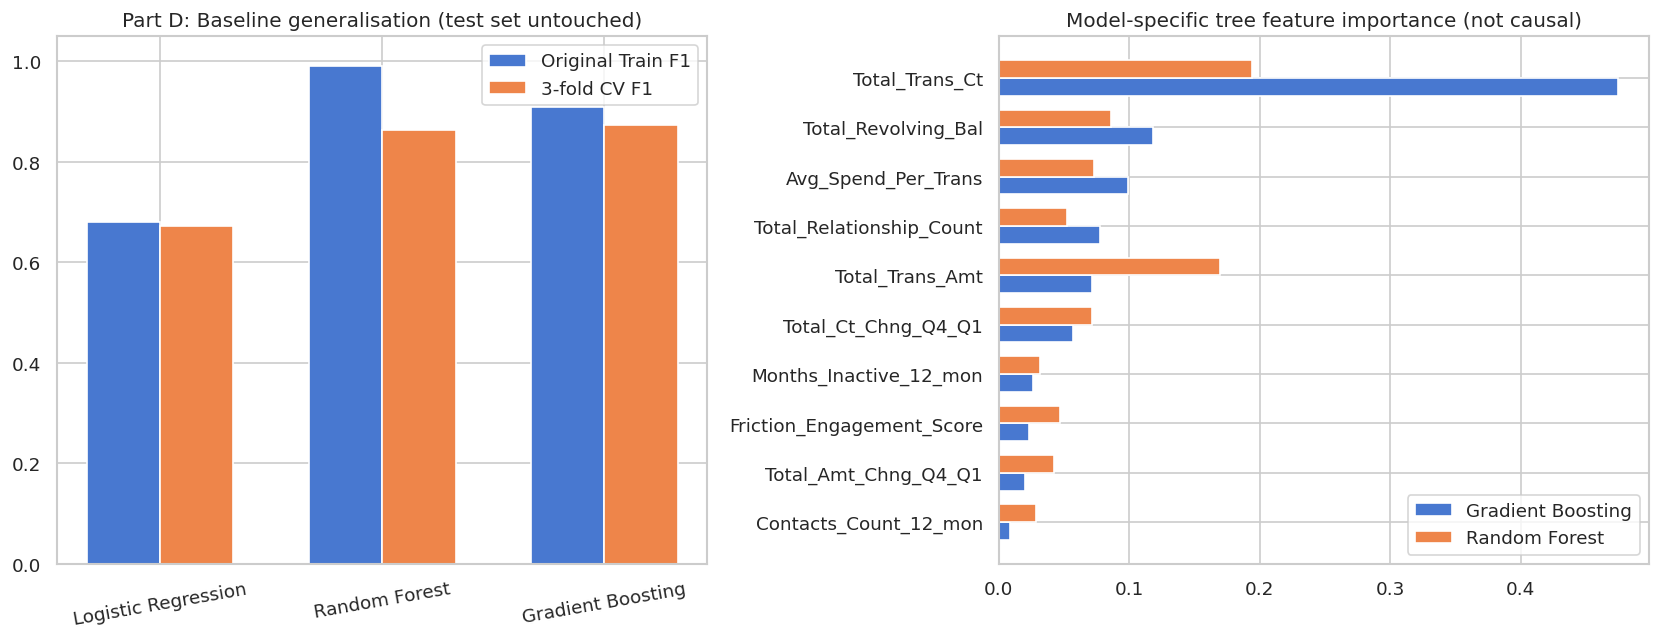


Top GB features:
Total_Trans_Ct               0.4746
Total_Revolving_Bal          0.1184
Avg_Spend_Per_Trans          0.0991
Total_Relationship_Count     0.0774
Total_Trans_Amt              0.0715
Total_Ct_Chng_Q4_Q1          0.0571
Months_Inactive_12_mon       0.0265
Friction_Engagement_Score    0.0234

Largest absolute LR coefficients (standardised numeric + one-hot categorical):
Avg_Spend_Per_Trans    2.8141
Total_Trans_Amt       -2.4641
Total_Trans_Ct        -1.4734
Marital_Status_0.0    -1.0825
Card_Category_3.0     -0.9387
Gender_1.0            -0.9152
Total_Ct_Chng_Q4_Q1   -0.7959
Total_Revolving_Bal   -0.7453


In [16]:
# Interpret the fitted baselines without looking at the test labels.
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
labels = part_d_df['Base Model']
xidx = np.arange(len(labels))
w = 0.33
axes[0].bar(xidx-w/2, part_d_df['Train_F1'], w, label='Original Train F1')
axes[0].bar(xidx+w/2, part_d_df['CV_F1_Mean'], w, label=f'{CV_SPLITS}-fold CV F1')
axes[0].set_xticks(xidx, labels, rotation=10)
axes[0].set_ylim(0, 1.05)
axes[0].set_title('Part D: Baseline generalisation (test set untouched)')
axes[0].legend()

rf_model = base_models['Random Forest']
gb_model = base_models['Gradient Boosting']
original_numeric = [c for c in X_train if pd.api.types.is_numeric_dtype(X_train[c])]
original_categorical = [c for c in X_train if c not in original_numeric]
feature_names = gb_model.named_steps['encode'].get_feature_names_out(
    input_features=original_numeric + original_categorical)
rf_imp = pd.Series(rf_model.named_steps['model'].feature_importances_, index=feature_names)
gb_imp = pd.Series(gb_model.named_steps['model'].feature_importances_, index=feature_names)
top10 = gb_imp.nlargest(10).sort_values().index
axes[1].barh(np.arange(len(top10))-.18, gb_imp[top10], .36, label='Gradient Boosting')
axes[1].barh(np.arange(len(top10))+.18, rf_imp.reindex(top10), .36, label='Random Forest')
axes[1].set_yticks(np.arange(len(top10)), top10)
axes[1].set_title('Model-specific tree feature importance (not causal)')
axes[1].legend()
plt.tight_layout()
plt.savefig('PartD_Baseline_Feature_Importance.png', dpi=180, bbox_inches='tight')
plt.show()
print('\nTop GB features:')
print(gb_imp.nlargest(8).round(4).to_string())
print('\nLargest absolute LR coefficients (standardised numeric + one-hot categorical):')
lr_weights = pd.Series(base_models['Logistic Regression'].named_steps['model'].coef_[0],
                       index=base_models['Logistic Regression'].named_steps['encode'].get_feature_names_out(
                           input_features=original_numeric+original_categorical))
print(lr_weights.loc[lr_weights.abs().nlargest(8).index].round(4).to_string())

## Part E — Hyperparameter optimisation (10 marks)
Apply 3-fold stratified CV to each complete Pipeline on the original training partition. Compare each tuned **CV F1** with the corresponding baseline **CV F1** (not test F1), report investigated parameters and selected values. Tuning can improve or reduce measured scores; do not claim improvement where none occurs. Small parameter grids are intentional for repeatable classroom execution; they do not establish global optima.

In [17]:
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

search_configs = {
    'Logistic Regression': GridSearchCV(
        build_pipeline(BASE_ESTIMATORS['Logistic Regression'], X_train.columns),
        param_grid={'model__C': [0.05, 0.2, 1.0, 5.0]},
        scoring='f1', cv=CV, n_jobs=1, refit=True, error_score='raise'),
    'Random Forest': RandomizedSearchCV(
        build_pipeline(BASE_ESTIMATORS['Random Forest'], X_train.columns),
        param_distributions={
            'model__n_estimators': [90, 130, 180],
            'model__max_depth': [None, 12, 20],
            'model__min_samples_leaf': [1, 2, 4]
        }, n_iter=5, scoring='f1', cv=CV, n_jobs=1,
        random_state=RANDOM_STATE, refit=True, error_score='raise'),
    'Gradient Boosting': RandomizedSearchCV(
        build_pipeline(BASE_ESTIMATORS['Gradient Boosting'], X_train.columns),
        param_distributions={
            'model__n_estimators': [80, 110, 140],
            'model__learning_rate': [0.07, 0.10, 0.14],
            'model__max_depth': [2, 3],
            'model__subsample': [0.85, 1.0]
        }, n_iter=5, scoring='f1', cv=CV, n_jobs=1,
        random_state=RANDOM_STATE, refit=True, error_score='raise')
}
tuned_models = {}
tuning_rows = []
for name, search in search_configs.items():
    print(f'\nHyperparameter tuning: {name}...')
    started = time.perf_counter()
    search.fit(X_train, y_train)  # CV folds each fit preprocessing + SMOTENC independently
    search_s = time.perf_counter()-started
    tuned_models[name] = search.best_estimator_
    baseline_row = part_d_df.set_index('Base Model').loc[name]
    train_f1 = f1_score(y_train, search.best_estimator_.predict(X_train), zero_division=0)
    tuning_rows.append({
        'Base Model': name,
        'Baseline_CV_F1': baseline_row['CV_F1_Mean'],
        'Tuned_CV_F1': search.best_score_,
        'Delta_CV_F1': search.best_score_ - baseline_row['CV_F1_Mean'],
        'Original_Train_F1': train_f1,
        'CV_Generalisation_Gap': train_f1-search.best_score_,
        'Best_Parameters': str(search.best_params_),
        'CV_Configurations': len(search.cv_results_['params']),
        'Search_And_Refit_s': search_s,
        'Final_Refit_s': float(search.refit_time_)
    })
df_part_e = pd.DataFrame(tuning_rows)
print('\n=== PART E: TUNED VS BASELINE (VALIDATION FOLDS ONLY) ===')
print(df_part_e.round(4).to_string(index=False))


Hyperparameter tuning: Logistic Regression...

Hyperparameter tuning: Random Forest...

Hyperparameter tuning: Gradient Boosting...

=== PART E: TUNED VS BASELINE (VALIDATION FOLDS ONLY) ===
         Base Model  Baseline_CV_F1  Tuned_CV_F1  Delta_CV_F1  Original_Train_F1  CV_Generalisation_Gap                                                                                            Best_Parameters  CV_Configurations  Search_And_Refit_s  Final_Refit_s
Logistic Regression          0.6721       0.6727       0.0006             0.6767                 0.0040                                                                                         {'model__C': 0.05}                  4              9.1023         0.9177
      Random Forest          0.8638       0.8660       0.0022             0.9893                 0.1234                          {'model__n_estimators': 90, 'model__min_samples_leaf': 2, 'model__max_depth': 20}                  5             54.5585         4.8898
  Gradient Bo

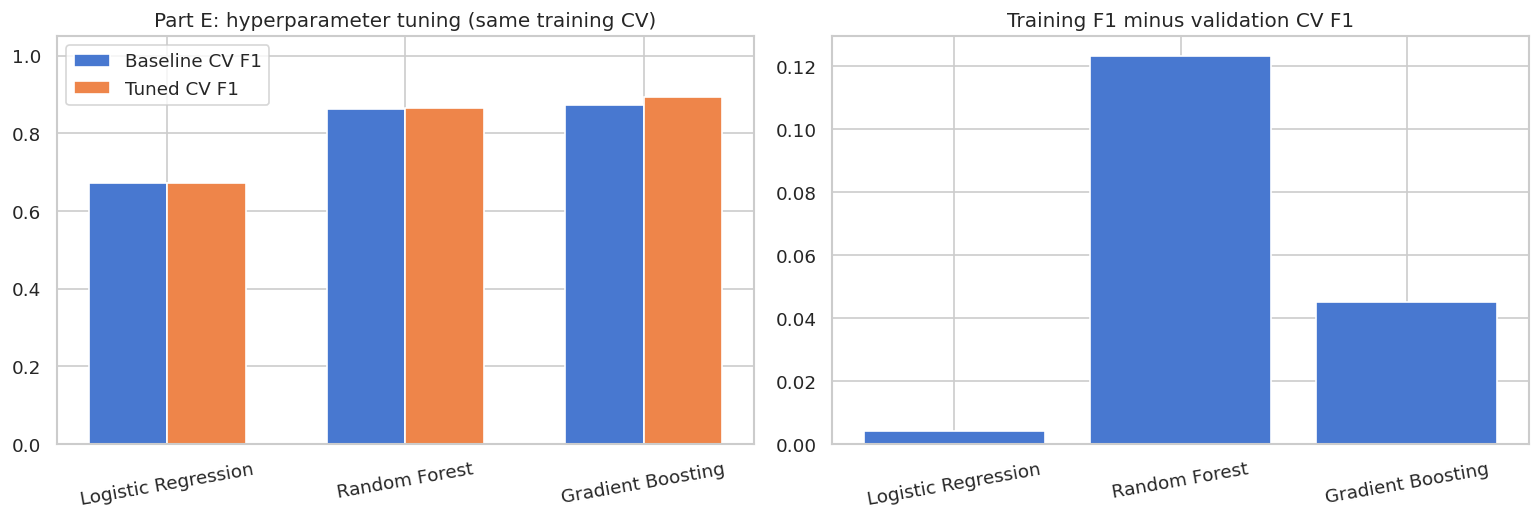

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pos = np.arange(len(df_part_e)); width = .33
axes[0].bar(pos-width/2, df_part_e['Baseline_CV_F1'], width, label='Baseline CV F1')
axes[0].bar(pos+width/2, df_part_e['Tuned_CV_F1'], width, label='Tuned CV F1')
axes[0].set_xticks(pos, df_part_e['Base Model'], rotation=10)
axes[0].set_ylim(0, 1.05); axes[0].set_title('Part E: hyperparameter tuning (same training CV)')
axes[0].legend()
axes[1].bar(df_part_e['Base Model'], df_part_e['CV_Generalisation_Gap'])
axes[1].set_title('Training F1 minus validation CV F1')
axes[1].tick_params(axis='x', rotation=10)
axes[1].axhline(0, color='black', lw=1)
plt.tight_layout(); plt.savefig('PartE_CV_Tuning.png', dpi=180, bbox_inches='tight'); plt.show()

## Part F — Ensemble model (10 marks)
Select exactly **two different tuned base algorithms** with the highest held-out-*fold* mean CV F1. Exclude the third based on the same validation metric. Use **soft voting**, averaging the two calibrated-or-uncalibrated model probabilities with equal weights. This is simple, reproducible and avoids another meta-learner; however probability calibration differences can limit performance. Evaluate the ensemble with cross-validation before ever opening the test set.

Two selected tuned base models (training CV F1): ['Gradient Boosting', 'Random Forest']
Third excluded model (lower training CV F1): Logistic Regression

=== PART F: TWO-MODEL ENSEMBLE (VALIDATION ONLY) ===
                                 Ensemble Model   Selected Base 1 Selected Base 2       Excluded Base  Train_F1_Original  CV_F1_Mean  CV_F1_SD  CV_Recall_Mean  CV_ROC_AUC_Mean  Fit_Time_s
Soft Voting (Gradient Boosting + Random Forest) Gradient Boosting   Random Forest Logistic Regression             0.9678      0.8891    0.0044          0.8986           0.9895       18.08


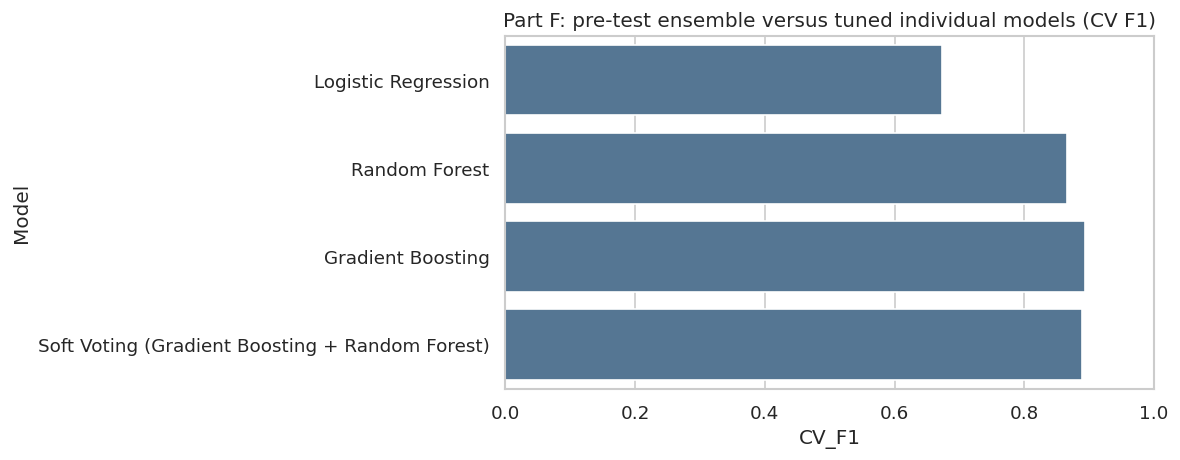

In [19]:
from sklearn.ensemble import VotingClassifier
selection = df_part_e.sort_values('Tuned_CV_F1', ascending=False).reset_index(drop=True)
chosen_two = selection['Base Model'].head(2).tolist()
excluded_one = selection['Base Model'].iloc[2]
print('Two selected tuned base models (training CV F1):', chosen_two)
print('Third excluded model (lower training CV F1):', excluded_one)

ensemble_name = 'Soft Voting (' + ' + '.join(chosen_two) + ')'
ensemble_candidate = VotingClassifier(
    estimators=[('m1', clone(tuned_models[chosen_two[0]])),
                ('m2', clone(tuned_models[chosen_two[1]]))],
    voting='soft', weights=[1, 1], n_jobs=1
)
ensemble_cv = fold_f1(ensemble_candidate, X_train, y_train)
started = time.perf_counter()
ensemble_candidate.fit(X_train, y_train)
ensemble_fit_s = time.perf_counter()-started
trained_ensembles = {ensemble_name: ensemble_candidate}
ensemble_train_f1 = f1_score(y_train, ensemble_candidate.predict(X_train), zero_division=0)
df_part_f = pd.DataFrame([{
    'Ensemble Model': ensemble_name,
    'Selected Base 1': chosen_two[0], 'Selected Base 2': chosen_two[1],
    'Excluded Base': excluded_one,
    'Train_F1_Original': ensemble_train_f1,
    'CV_F1_Mean': ensemble_cv['test_f1'].mean(),
    'CV_F1_SD': ensemble_cv['test_f1'].std(),
    'CV_Recall_Mean': ensemble_cv['test_recall'].mean(),
    'CV_ROC_AUC_Mean': ensemble_cv['test_roc_auc'].mean(),
    'Fit_Time_s': ensemble_fit_s
}])
print('\n=== PART F: TWO-MODEL ENSEMBLE (VALIDATION ONLY) ===')
print(df_part_f.round(4).to_string(index=False))

compare_cv = pd.concat([
    df_part_e[['Base Model', 'Tuned_CV_F1']].rename(
        columns={'Base Model':'Model','Tuned_CV_F1':'CV_F1'}),
    pd.DataFrame([{'Model':ensemble_name, 'CV_F1':df_part_f['CV_F1_Mean'].iloc[0]}])
], ignore_index=True)
plt.figure(figsize=(10,4)); sns.barplot(data=compare_cv, x='CV_F1', y='Model', color='#4b769d')
plt.xlim(0,1.0); plt.title('Part F: pre-test ensemble versus tuned individual models (CV F1)')
plt.tight_layout(); plt.savefig('PartF_Ensemble_CV_Comparison.png', dpi=180, bbox_inches='tight'); plt.show()

## Part G — Final independent test evaluation & comparative analysis (15 marks)
**Only in this part** are the four frozen/fitted models evaluated on the original untouched hold-out set. Present Accuracy, Precision, Recall, F1, ROC-AUC, PR-AUC and all four confusion matrices, plus training/CV gaps and computational efficiency. The highest test F1 is a descriptive deployment recommendation, **not a trigger for new tuning**. Pairwise bootstrap intervals quantify uncertainty in the ensemble-versus-best-base difference; a single split cannot prove universal model superiority. Economic costs and prospective prediction validity still need business validation.

In [20]:
# FINAL TEST USE: no parameter search or selection is performed after this point.
final_models = {
    'Logistic Regression': tuned_models['Logistic Regression'],
    'Random Forest': tuned_models['Random Forest'],
    'Gradient Boosting': tuned_models['Gradient Boosting'],
    ensemble_name: trained_ensembles[ensemble_name]
}
cv_lookup = dict(zip(df_part_e['Base Model'], df_part_e['Tuned_CV_F1']))
cv_lookup[ensemble_name] = float(df_part_f['CV_F1_Mean'].iloc[0])
fit_times = dict(zip(df_part_e['Base Model'], df_part_e['Final_Refit_s']))
fit_times[ensemble_name] = ensemble_fit_s
results=[]; cm_dict={}; roc_dict={}; saved_predictions={}
for name, model in final_models.items():
    train_pred = model.predict(X_train)  # use ORIGINAL training class prevalence
    t0 = time.perf_counter()
    pred = model.predict(X_test)
    proba = model.predict_proba(X_test)[:,1]
    infer_ms = (time.perf_counter()-t0)*1000
    saved_predictions[name] = (pred, proba)
    cm = confusion_matrix(y_test, pred, labels=[0,1])
    cm_dict[name] = cm
    fpr,tpr,_ = roc_curve(y_test,proba)
    roc_dict[name] = (fpr,tpr,roc_auc_score(y_test,proba))
    tn,fp,fn,tp = cm.ravel()
    train_f1 = f1_score(y_train,train_pred,zero_division=0)
    test_f1 = f1_score(y_test,pred,zero_division=0)
    results.append({
        'Model':name,
        'Accuracy':accuracy_score(y_test,pred),
        'Precision':precision_score(y_test,pred,zero_division=0),
        'Recall':recall_score(y_test,pred,zero_division=0),
        'F1':test_f1,
        'ROC_AUC':roc_auc_score(y_test,proba),
        'PR_AUC':average_precision_score(y_test,proba),
        'Train_F1_Original':train_f1,
        'CV_F1':cv_lookup[name],
        'Train_minus_CV_F1':train_f1-cv_lookup[name],
        'Train_minus_Test_F1':train_f1-test_f1,
        'Fit_Time_s':fit_times[name],
        'Test_Predict_Time_ms':infer_ms,
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp)
    })
df_part_g = pd.DataFrame(results)
print('\n=== PART G: FOUR FINAL MODELS ON ONE UNTOUCHED TEST SET ===')
print(df_part_g.round(4).to_string(index=False))
df_part_g.to_csv('PartG_Final_Model_Comparison.csv', index=False)

# Test results can inform a final descriptive recommendation; do not tune on them.
recommendation = df_part_g.sort_values(['F1','ROC_AUC'],ascending=False).iloc[0]
print('\nDeployment candidate based on observed final test F1:', recommendation['Model'])
print('Caution: prospective timing, false-alarm cost, and robustness need real-world validation.')


=== PART G: FOUR FINAL MODELS ON ONE UNTOUCHED TEST SET ===
                                          Model  Accuracy  Precision  Recall     F1  ROC_AUC  PR_AUC  Train_F1_Original  CV_F1  Train_minus_CV_F1  Train_minus_Test_F1  Fit_Time_s  Test_Predict_Time_ms   TN  FP  FN  TP
                            Logistic Regression    0.8687     0.5648  0.7908 0.6590   0.9243  0.7405             0.6767 0.6727             0.0040               0.0177      0.9177               24.7041 1503 198  68 257
                                  Random Forest    0.9506     0.8483  0.8431 0.8457   0.9841  0.9354             0.9893 0.8660             0.1234               0.1437      4.8898               86.5808 1652  49  51 274
                              Gradient Boosting    0.9650     0.8896  0.8923 0.8909   0.9886  0.9554             0.9385 0.8936             0.0449               0.0476     13.0470               36.8553 1665  36  35 290
Soft Voting (Gradient Boosting + Random Forest)    0.9585     0.873

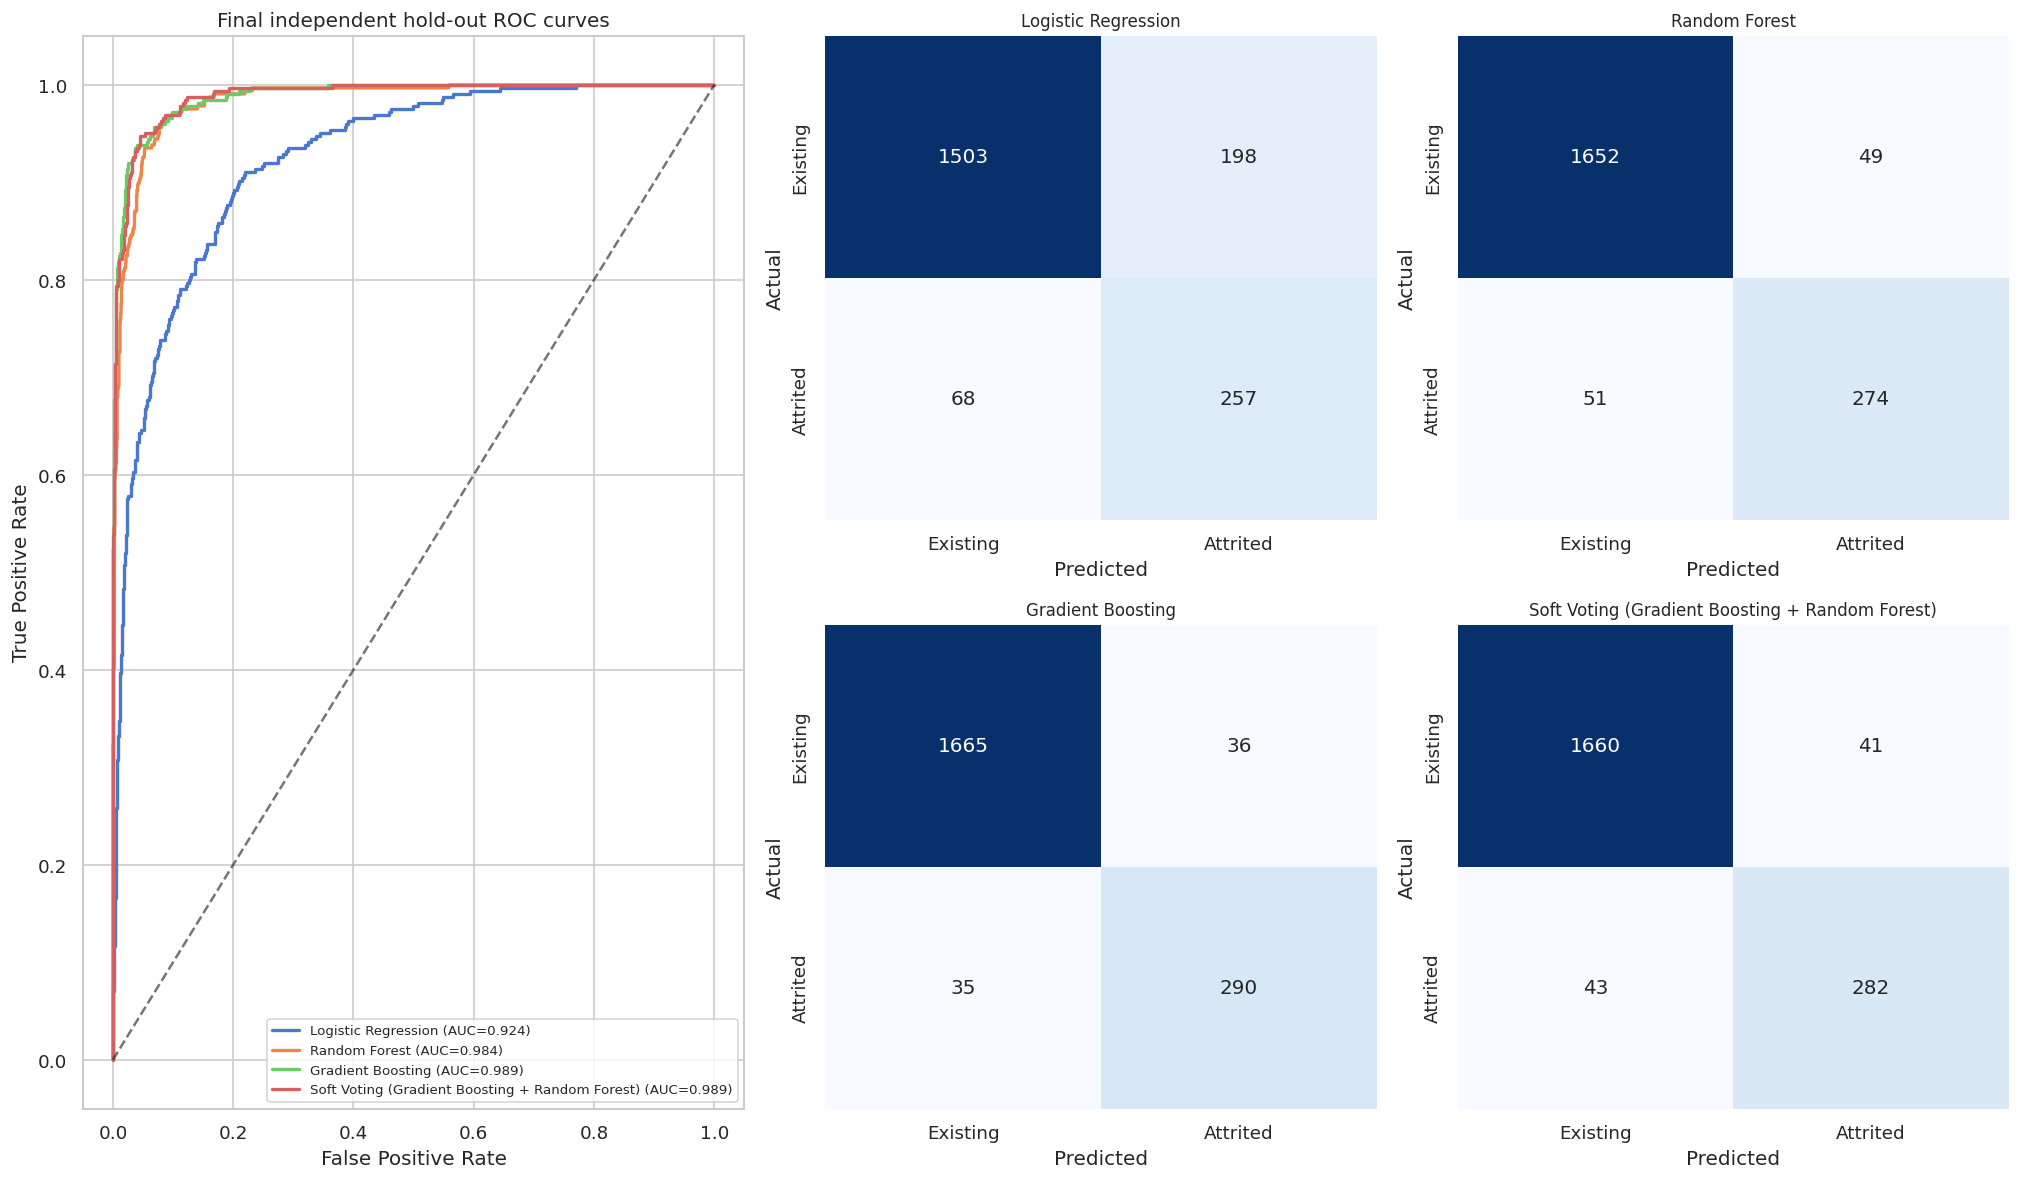

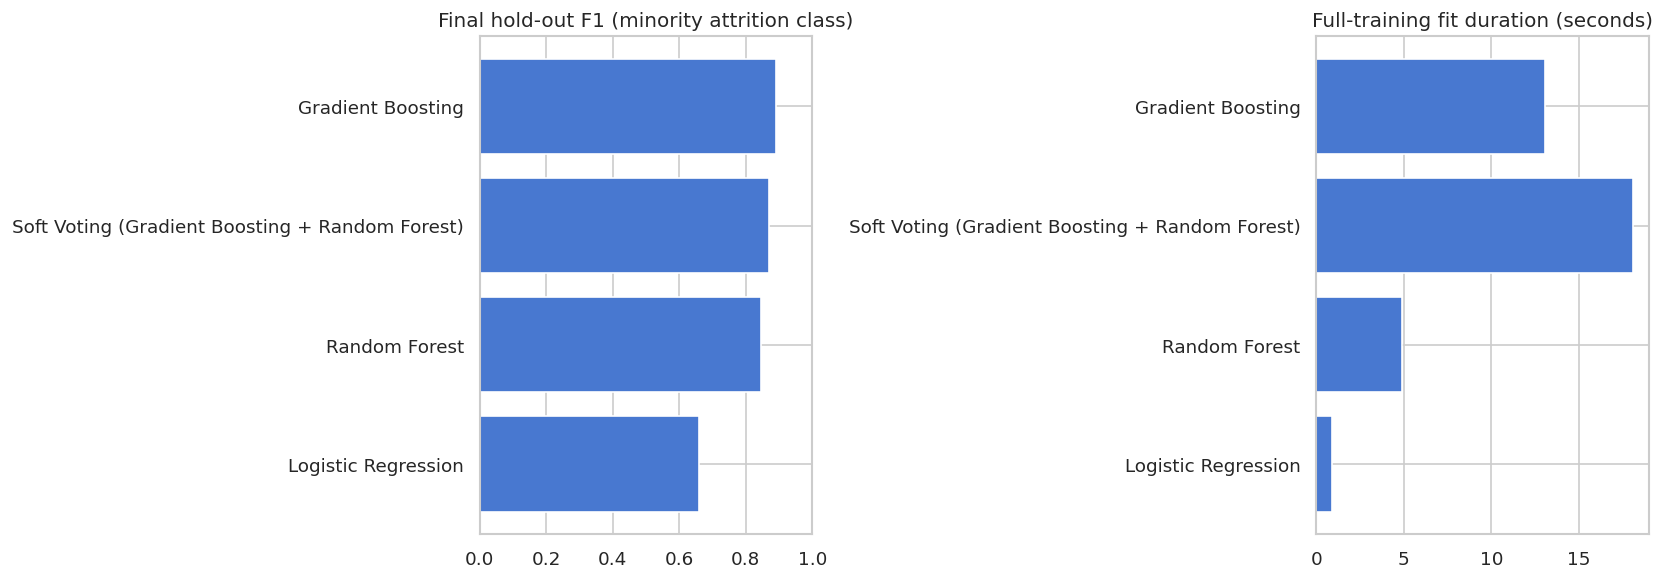

In [21]:
fig=plt.figure(figsize=(17,10))
gs=fig.add_gridspec(2,3,width_ratios=[1.2,1,1],height_ratios=[1,1])
ax=fig.add_subplot(gs[:,0])
for name,(fpr,tpr,auc) in roc_dict.items():
    ax.plot(fpr,tpr,lw=2,label=f'{name} (AUC={auc:.3f})')
ax.plot([0,1],[0,1],'k--',alpha=.6)
ax.set_xlabel('False Positive Rate');ax.set_ylabel('True Positive Rate')
ax.set_title('Final independent hold-out ROC curves')
ax.legend(fontsize=8,loc='lower right')
for i,(name,cm) in enumerate(cm_dict.items()):
    rr=i//2;cc=i%2+1
    h=fig.add_subplot(gs[rr,cc])
    sns.heatmap(cm,annot=True,fmt='d',cmap='Blues',cbar=False,ax=h,
                xticklabels=['Existing','Attrited'],yticklabels=['Existing','Attrited'])
    h.set_title(name,fontsize=10);h.set_xlabel('Predicted');h.set_ylabel('Actual')
plt.tight_layout();plt.savefig('PartG_Final_ROC_and_Confusion_Matrices.png',dpi=180,bbox_inches='tight');plt.show()

fig,axes=plt.subplots(1,2,figsize=(14,5))
order=df_part_g.sort_values('F1')
axes[0].barh(order['Model'],order['F1'])
axes[0].set_xlim(0,1);axes[0].set_title('Final hold-out F1 (minority attrition class)')
axes[1].barh(order['Model'],order['Fit_Time_s'])
axes[1].set_title('Full-training fit duration (seconds)')
plt.tight_layout();plt.savefig('PartG_F1_And_Runtime_Comparison.png',dpi=180,bbox_inches='tight');plt.show()

In [22]:
# Paired bootstrap CI for the F1 difference: ensemble minus strongest base model.
# This is an uncertainty check only, not a new tuning/selection procedure.
base_only = df_part_g[df_part_g['Model'] != ensemble_name]
best_base_name = base_only.sort_values('F1',ascending=False)['Model'].iloc[0]
a = saved_predictions[ensemble_name][0]
b = saved_predictions[best_base_name][0]
y_true = np.asarray(y_test)
rng = np.random.default_rng(RANDOM_STATE)
boot_differences = []
for _ in range(500):
    rows = rng.integers(0,len(y_true),size=len(y_true))
    boot_differences.append(f1_score(y_true[rows],a[rows],zero_division=0) -
                            f1_score(y_true[rows],b[rows],zero_division=0))
lo,hi = np.percentile(boot_differences,[2.5,97.5])
point_diff = f1_score(y_true,a)-f1_score(y_true,b)
print(f'Ensemble – best base ({best_base_name}) F1 difference: {point_diff:+.4f}')
print(f'Paired bootstrap 95% interval (500 resamples): [{lo:+.4f}, {hi:+.4f}]')
print('Interval spanning zero means the observed difference is not clearly separated from zero.')

Ensemble – best base (Gradient Boosting) F1 difference: -0.0206
Paired bootstrap 95% interval (500 resamples): [-0.0377, -0.0054]
Interval spanning zero means the observed difference is not clearly separated from zero.
